In [123]:
import pandas as pd 
print("hello")

hello


In [124]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [125]:
import pandas as pd
df = pd.read_csv("zomato.csv", encoding='latin1')
df = df[df['Country Code'] == 1] 
df = df[df['Average Cost for two'] < 10000]
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
624,3400025,Jahanpanah,1,Agra,"E 23, Shopping Arcade, Sadar Bazaar, Agra Cant...",Agra Cantt,"Agra Cantt, Agra",78.011544,27.161661,"North Indian, Mughlai",...,Indian Rupees(Rs.),No,No,No,No,3,3.9,Yellow,Good,140
625,3400341,Rangrezz Restaurant,1,Agra,"E-20, Shopping Arcade, Sadar Bazaar, Agra Cant...",Agra Cantt,"Agra Cantt, Agra",0.000000,0.000000,"North Indian, Mughlai",...,Indian Rupees(Rs.),No,No,No,No,2,3.5,Yellow,Good,71
626,3400005,Time2Eat - Mama Chicken,1,Agra,"Main Market, Sadar Bazaar, Agra Cantt, Agra",Agra Cantt,"Agra Cantt, Agra",78.011608,27.160832,North Indian,...,Indian Rupees(Rs.),No,No,No,No,2,3.6,Yellow,Good,94
627,3400021,Chokho Jeeman Marwari Jain Bhojanalya,1,Agra,"1/48, Delhi Gate, Station Road, Raja Mandi, Ci...",Civil Lines,"Civil Lines, Agra",77.998092,27.195928,Rajasthani,...,Indian Rupees(Rs.),No,No,No,No,2,4.0,Green,Very Good,87
628,3400017,Pinch Of Spice,1,Agra,"23/453, Opposite Sanjay Cinema, Wazipura Road,...",Civil Lines,"Civil Lines, Agra",78.007553,27.201725,"North Indian, Chinese, Mughlai",...,Indian Rupees(Rs.),No,No,No,No,3,4.2,Green,Very Good,177


In [126]:
print(df.shape)
print(df.columns.tolist())

(8652, 21)
['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Aggregate rating', 'Rating color', 'Rating text', 'Votes']


In [127]:
df['City'].value_counts().head(10)

City
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Ahmedabad         21
Amritsar          21
Bhubaneshwar      21
Guwahati          21
Lucknow           21
Name: count, dtype: int64

In [128]:
df ['Rating text'].value_counts()

Rating text
Average      3678
Not rated    2139
Good         1847
Very Good     692
Poor          180
Excellent     116
Name: count, dtype: int64

In [129]:
df.groupby('Has Online delivery')['Aggregate rating'].mean()

Has Online delivery
No     2.244999
Yes    3.238836
Name: Aggregate rating, dtype: float64

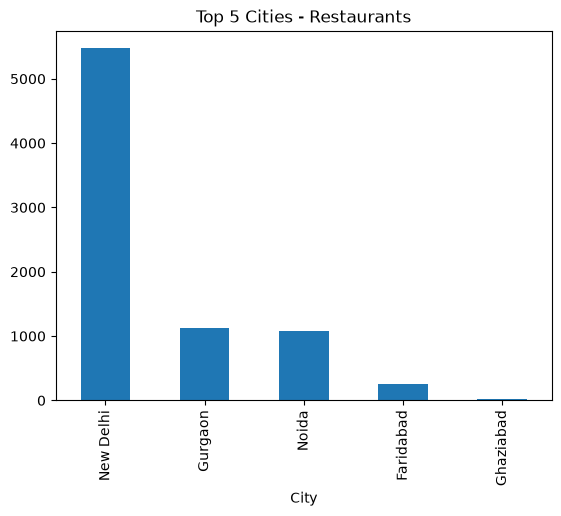

In [130]:
import matplotlib.pyplot as plt
df['City'].value_counts().head(5).plot(kind='bar')
plt.title('Top 5 Cities - Restaurants')
plt.show()

In [131]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


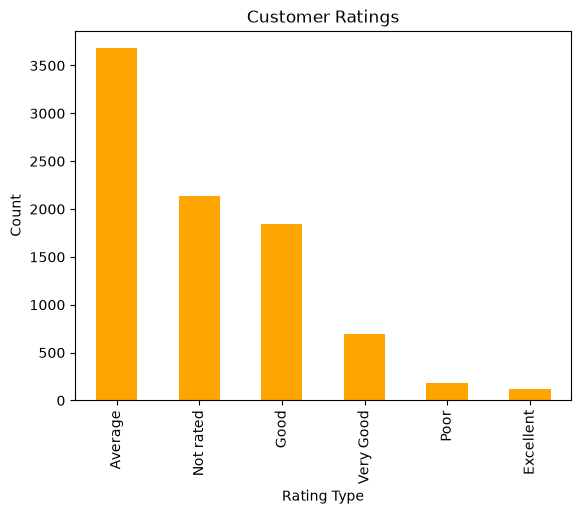

In [132]:
import matplotlib.pyplot as plt

df['Rating text'].value_counts().plot(kind='bar', color='orange')
plt.title('Customer Ratings')
plt.xlabel('Rating Type')
plt.ylabel('Count')
plt.show()

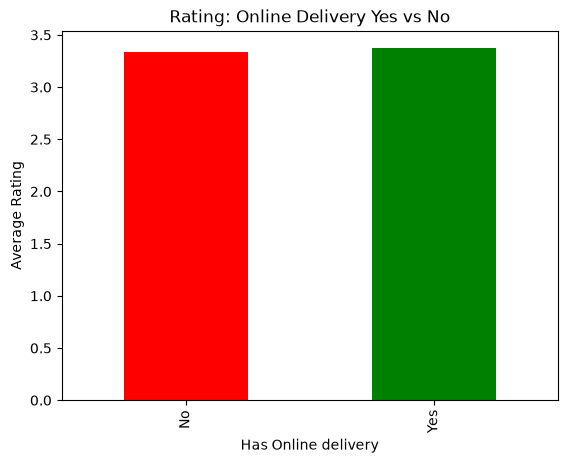

In [133]:
df_rated = df[df['Aggregate rating'] > 0]
df_rated.groupby('Has Online delivery')['Aggregate rating'].mean().plot(kind='bar', color=['red','green'])
plt.title('Rating: Online Delivery Yes vs No')
plt.ylabel('Average Rating')
plt.show()

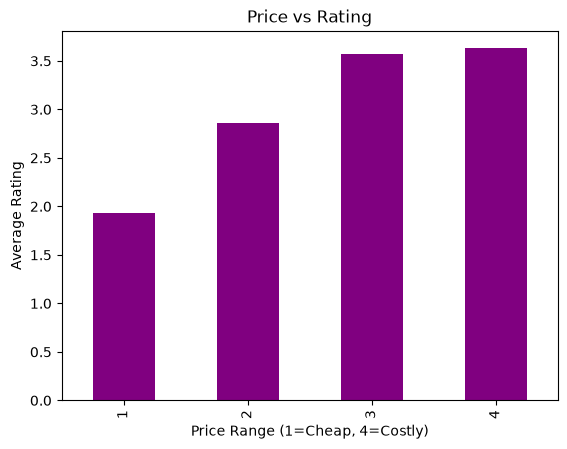

In [134]:
df.groupby('Price range')['Aggregate rating'].mean().plot(kind='bar', color='purple')
plt.title('Price vs Rating')
plt.xlabel('Price Range (1=Cheap, 4=Costly)')
plt.ylabel('Average Rating')
plt.show()

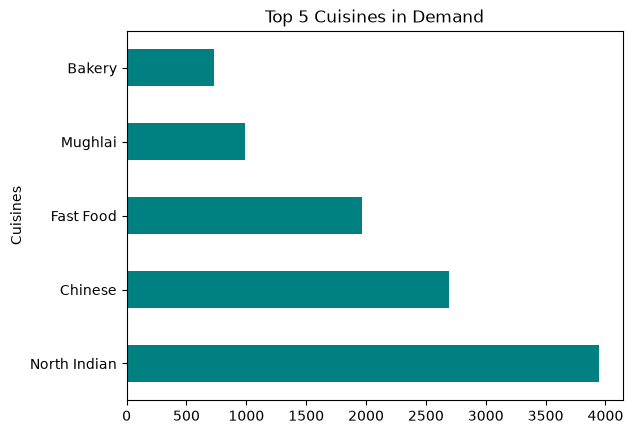

In [135]:
df['Cuisines'].str.split(', ').explode().value_counts().head(5).plot(kind='barh', color='teal')
plt.title('Top 5 Cuisines in Demand')
plt.show()

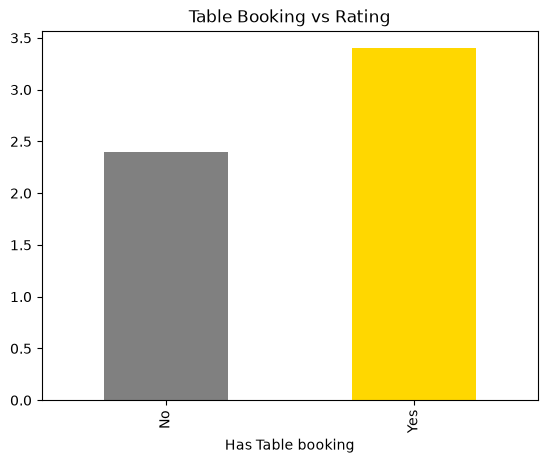

In [136]:
df.groupby('Has Table booking')['Aggregate rating'].mean().plot(kind='bar', color=['grey','gold'])
plt.title('Table Booking vs Rating')
plt.show()

In [137]:
df.isnull().sum()

Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                0
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64

In [138]:
df = df[df['Average Cost for two'] < 10000]

In [139]:
df.sort_values(by='Votes', ascending=False).head(5)[['Restaurant Name','City','Votes','Aggregate rating']]

,Restaurant Name,City,Votes,Aggregate rating
728,Toit,Bangalore,10934,4.8
735,Truffles,Bangalore,9667,4.7
3994,Hauz Khas Social,New Delhi,7931,4.3
2412,Peter Cat,Kolkata,7574,4.3
739,AB's - Absolute Barbecues,Bangalore,6907,4.6


In [140]:
df[(df['Price range']==4) & (df['Aggregate rating']>4.5)][['Restaurant Name','Aggregate rating','City']].head(5)

,Restaurant Name,Aggregate rating,City
727,The Fatty Bao - Asian Gastro Bar,4.7,Bangalore
728,Toit,4.8,Bangalore
850,The Great Indian Pub,4.9,Dehradun
1142,Burger Factory,4.8,Goa
1154,The Fisherman's Wharf,4.6,Goa


In [141]:
df['Expensive'] = df['Price range'].apply(lambda x: 'Costly' if x>=3 else 'Cheap')
df['Expensive'].value_counts()

Expensive
Cheap     7153
Costly    1499
Name: count, dtype: int64

In [142]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


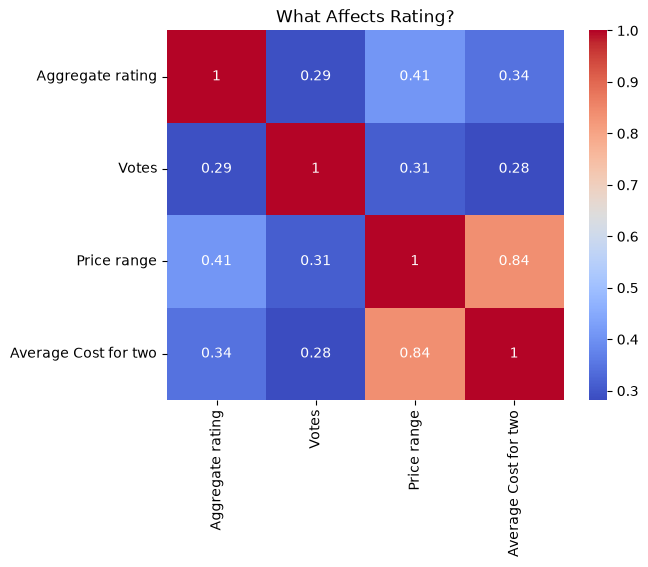

In [143]:
import seaborn as sns
sns.heatmap(df[['Aggregate rating','Votes','Price range','Average Cost for two']].corr(), annot=True, cmap='coolwarm')
plt.title('What Affects Rating?')
plt.show()

In [144]:
df.groupby('City')['Aggregate rating'].mean().sort_values(ascending=False).head(10)

City
Secunderabad    4.500000
Bangalore       4.375000
Hyderabad       4.344444
Chennai         4.315000
Mohali          4.300000
Kolkata         4.255000
Goa             4.245000
Pune            4.220000
Panchkula       4.200000
Lucknow         4.195238
Name: Aggregate rating, dtype: float64

In [145]:
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


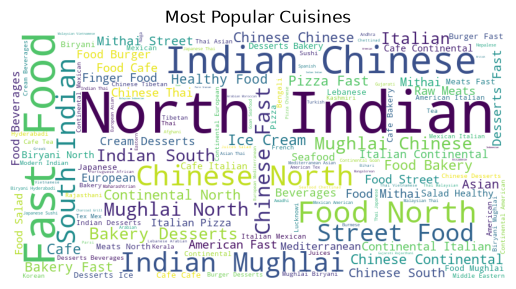

In [146]:
from wordcloud import WordCloud
text = " ".join(df['Cuisines'].dropna())
wc = WordCloud(width=800, height=400, background_color='white').generate(text)
plt.imshow(wc)
plt.axis('off')
plt.title('Most Popular Cuisines')
plt.show()

In [147]:
df_clean = df.dropna(subset=['Cuisines','Aggregate rating'])
df_clean.to_csv('zomato_for_powerbi.csv', index=False)
print("File ready for Power BI! Shape:", df_clean.shape)

File ready for Power BI! Shape: (8652, 22)


In [148]:
df_clean.to_csv('zomato_for_powerbi.csv', index=False, encoding='utf-8', quoting=1)
print("Fixed file saved!")

Fixed file saved!


In [149]:
import pandas as pd
import csv
df = pd.read_csv('zomato_for_powerbi.csv')
df['City'] = df['City'].astype(str).str.replace('"', '', regex=False).str.strip()
df['Has Table booking'] = df['Has Table booking'].astype(str).str.strip()
df = df[df['Has Table booking'].isin(['Yes', 'No'])]
df.to_csv('zomato_for_powerbi.csv', index=False, encoding='utf-8-sig', quoting=csv.QUOTE_ALL)
print(f"Done! {df.shape} - Now 0 errors")

Done! (8652, 22) - Now 0 errors


In [150]:
import pandas as pd
df = pd.read_csv('zomato_for_powerbi.csv')
print("Rows:", len(df))

Rows: 8652


In [151]:

print("Before:", df.shape)
df_clean = df.dropna(subset=['Cuisines'])
df_clean = df_clean[df_clean['Has Table booking'].isin(['Yes','No'])]
print("After:", df_clean.shape)
df_clean.to_csv('zomato_for_powerbi.csv', index=False, encoding='utf-8-sig')

Before: (8652, 22)
After: (8652, 22)


In [153]:
print("Before:", df.shape) # 8652 vastundi
df = df.dropna()
df = df[df['Cuisines'].str.strip() != '']
df = df[df['City'].str.strip() != '']
df = df[df['Average Cost for two'] > 0]
df = df[df['Votes'] >= 0]
print("After:", df.shape) 
df.to_csv('zomato_for_powerbi.csv', index=False, encoding='utf-8-sig')
print("Saved! Final rows:", len(df))

Before: (8652, 22)
After: (8643, 22)
Saved! Final rows: 8643
